# 02 · Entendimento dos dados (EDA)

Fase 2 do CRISP-DM. Responde às perguntas analíticas 1, 2, 3, 5 e 6 do relatório das Etapas 1 e 2 sobre a tabela analítica (`dados/tabela_analitica.csv`, gerada pelo notebook 01).

- Unidade: escola × etapa (rede pública, matrícula ≥ 10 na etapa).
- Alvo de referência: taxa de abandono ≥ P80 da etapa (anos iniciais: taxa > 0, pois o P80 é zero).
- Associações não implicam causalidade. A geografia (pergunta 8) está no notebook 04, com o cálculo proporcional.
- A pergunta 7 (Ideb-aprendizagem) não foi executada: não há coluna de aprendizagem validada contra vazamento temporal.

In [1]:
import os

REPO = "datasync-Projeto-CRISP-DM-abandono"
if not os.path.exists(REPO) and os.path.basename(os.getcwd()) != REPO:
    !git clone -q https://github.com/LuisGomes25/{REPO}.git
if os.path.basename(os.getcwd()) != REPO:
    os.chdir(REPO)

SAIDA = "resultados/02_eda"
os.makedirs(SAIDA, exist_ok=True)
print("Pasta de trabalho:", os.getcwd())

Pasta de trabalho: /content/datasync-Projeto-CRISP-DM-abandono


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
ETAPAS = ["ensino_medio", "anos_finais", "anos_iniciais"]

GRUPOS_VARIAVEIS = {
    "estruturais": ["indice_infra", "pct_transporte_publico", "pct_integral", "pct_noturno"],
    "docentes": ["afd_formacao_adequada", "dsu_doc_superior", "ied_esforco_alto", "ird_regularidade"],
    "pedagogicas": ["atu_alunos_turma", "had_horas_aula"],
    "gestao": ["icg_complexidade"],
    "contextuais": ["inse_media", "tdi_distorcao", "log_matriculas", "alunos_por_docente"],
}
NUMERICAS = [v for vs in GRUPOS_VARIAVEIS.values() for v in vs]
CATEGORICAS = ["SG_UF", "NO_CATEGORIA", "NO_DEPENDENCIA"]

df = pd.read_csv("dados/tabela_analitica.csv", encoding="utf-8-sig",
                 dtype={"codigo_escola": str, "CO_MUNICIPIO": str}, low_memory=False)
assert df.shape == (136713, 27), df.shape

def criar_alvo(serie, percentil=80):
    """Alto abandono por percentil da etapa; se o limite for zero, usa taxa > 0."""
    limite = float(serie.quantile(percentil / 100))
    if limite == 0.0:
        return (serie > 0).astype(int), limite
    return (serie >= limite).astype(int), limite

df["alvo_p80"] = 0
for etapa in ETAPAS:
    mask = df["etapa"] == etapa
    df.loc[mask, "alvo_p80"] = criar_alvo(df.loc[mask, "taxa_abandono"])[0].values

def salvar(tabela, nome, **kw):
    tabela.to_csv(os.path.join(SAIDA, nome), encoding="utf-8-sig", **kw)

print(df.groupby("etapa")["alvo_p80"].agg(["size", "mean"]).round(4))

                size    mean
etapa                       
anos_finais    44803  0.2012
anos_iniciais  70681  0.1528
ensino_medio   21229  0.2003


## Pergunta 1 · Distribuição do abandono por etapa, rede, localização e UF

In [3]:
def resumo(grupo):
    return grupo["taxa_abandono"].agg(
        linhas="size", media="mean", mediana="median", desvio="std",
        p75=lambda s: s.quantile(.75), p80=lambda s: s.quantile(.80), p90=lambda s: s.quantile(.90),
        pct_zero=lambda s: (s == 0).mean() * 100,
    ).round(3)

por_etapa = resumo(df.groupby("etapa"))
por_rede = resumo(df.groupby(["etapa", "NO_DEPENDENCIA"]))
por_localizacao = resumo(df.groupby(["etapa", "NO_CATEGORIA"]))
por_uf = resumo(df.groupby(["etapa", "SG_UF"]))

for tabela, nome in [(por_etapa, "01_por_etapa.csv"), (por_rede, "02_por_rede.csv"),
                     (por_localizacao, "03_por_localizacao.csv"), (por_uf, "04_por_uf.csv")]:
    salvar(tabela, nome)
display(por_etapa, por_rede, por_localizacao)

,linhas,media,mediana,desvio,p75,p80,p90,pct_zero
etapa,,,,,,,,
anos_finais,44803,1.287,0.0,3.485,1.3,1.8,3.6,58.922
anos_iniciais,70681,0.305,0.0,1.601,0.0,0.0,0.6,84.719
ensino_medio,21229,2.498,1.0,4.087,3.5,4.4,6.9,38.052


linhas  media  mediana  desvio    p75   p80  \
etapa         NO_DEPENDENCIA                                                
anos_finais   Estadual         17580  1.126      0.0   3.250  1.200  1.60   
              Federal             42  0.995      0.0   4.423  0.200  0.28   
              Municipal        27181  1.391      0.0   3.625  1.300  1.90   
anos_iniciais Estadual          7788  0.557      0.0   2.915  0.000  0.30   
              Federal             25  0.036      0.0   0.125  0.000  0.00   
              Municipal        62868  0.274      0.0   1.349  0.000  0.00   
ensino_medio  Estadual         20413  2.524      1.0   4.021  3.600  4.40   
              Federal            624  1.373      0.6   4.352  1.600  2.00   
              Municipal          192  3.440      0.0   7.849  2.925  4.36   

                               p90  pct_zero  
etapa         NO_DEPENDENCIA                  
anos_finais   Estadual        3.10    56.047  
              Federal         0.50    66.667  
              Municipal       4.10    60.770  
anos_iniciais Estadual        1.10    77.324  
              Federal         0.06    88.000  
              Municipal       0.50    85.633  
ensino_medio  Estadual        7.00    38.128  
              Federal         3.30    30.288  
              Municipal       9.89    55.208

linhas  media  mediana  desvio  p75  p80  p90  \
etapa         NO_CATEGORIA                                                  
anos_finais   Rural          16375  1.949      0.0   5.112  1.7  2.6  6.0   
              Urbana         28428  0.905      0.0   1.922  1.1  1.5  2.8   
anos_iniciais Rural          34666  0.390      0.0   2.131  0.0  0.0  0.0   
              Urbana         36015  0.223      0.0   0.802  0.0  0.2  0.7   
ensino_medio  Rural           3397  3.213      0.0   6.427  3.9  5.1  9.2   
              Urbana         17832  2.362      1.0   3.450  3.5  4.3  6.6   

                            pct_zero  
etapa         NO_CATEGORIA            
anos_finais   Rural           67.176  
              Urbana          54.168  
anos_iniciais Rural           91.283  
              Urbana          78.401  
ensino_medio  Rural           50.015  
              Urbana          35.773

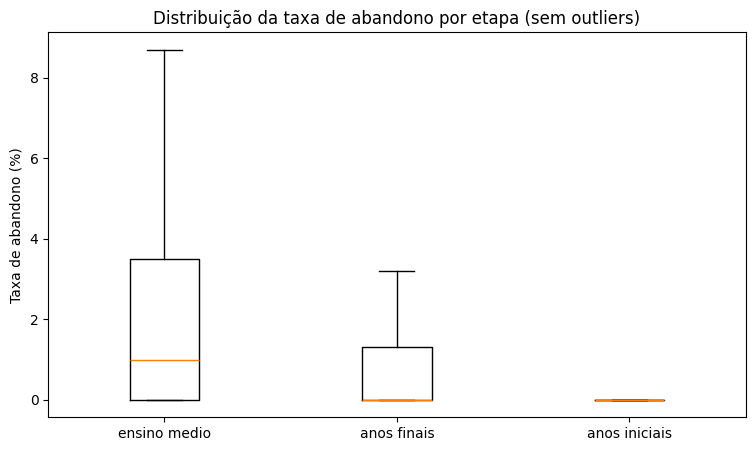

In [4]:
fig, eixo = plt.subplots(figsize=(9, 5))
eixo.boxplot([df.loc[df["etapa"] == e, "taxa_abandono"] for e in ETAPAS], showfliers=False)
eixo.set_xticks([1, 2, 3], [e.replace("_", " ") for e in ETAPAS])
eixo.set_ylabel("Taxa de abandono (%)")
eixo.set_title("Distribuição da taxa de abandono por etapa (sem outliers)")
plt.savefig(os.path.join(SAIDA, "01_boxplot_etapa.png"), dpi=300, bbox_inches="tight")
plt.show()

## Pergunta 2 · Fatores associados ao alto abandono

In [5]:
from scipy.stats import spearmanr, pointbiserialr, chi2_contingency

linhas = []
for etapa in ETAPAS:
    d = df[df["etapa"] == etapa]
    for grupo, variaveis in GRUPOS_VARIAVEIS.items():
        for var in variaveis:
            par = d[[var, "taxa_abandono", "alvo_p80"]].dropna()
            rho, p_rho = spearmanr(par[var], par["taxa_abandono"])
            r_pb, p_pb = pointbiserialr(par["alvo_p80"], par[var])
            linhas.append({"etapa": etapa, "grupo": grupo, "variavel": var, "n": len(par),
                           "spearman_taxa": rho, "p_spearman": p_rho,
                           "ponto_bisserial_alvo": r_pb, "p_ponto_bisserial": p_pb})
assoc = pd.DataFrame(linhas).round(4)
salvar(assoc, "05_associacoes_numericas.csv", index=False)

def cramers_v(x, y):
    tabela = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabela)[0]
    n = tabela.values.sum()
    r, k = tabela.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_c, k_c = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(k_c - 1, r_c - 1))

cramer = pd.DataFrame([{"etapa": e, "variavel": c,
                        "cramers_v": cramers_v(df.loc[df["etapa"] == e, c], df.loc[df["etapa"] == e, "alvo_p80"])}
                       for e in ETAPAS for c in CATEGORICAS]).round(3)
salvar(cramer, "06_cramers_v.csv", index=False)

display(assoc.sort_values("spearman_taxa", key=abs, ascending=False).groupby("etapa").head(5), cramer)

,etapa,grupo,variavel,n,spearman_taxa,p_spearman,ponto_bisserial_alvo,p_ponto_bisserial
27,anos_finais,contextuais,tdi_distorcao,44800,0.3019,0.0,0.3456,0.0000
12,ensino_medio,contextuais,tdi_distorcao,21072,0.2519,0.0,0.2539,0.0000
43,anos_iniciais,contextuais,log_matriculas,70681,0.2289,0.0,0.2532,0.0000
42,anos_iniciais,contextuais,tdi_distorcao,70675,0.2162,0.0,0.1859,0.0000
38,anos_iniciais,pedagogicas,atu_alunos_turma,54686,0.2004,0.0,0.2192,0.0000
3,ensino_medio,estruturais,pct_noturno,21229,0.1949,0.0,0.1694,0.0000
10,ensino_medio,gestao,icg_complexidade,21229,0.1775,0.0,0.0846,0.0000
44,anos_iniciais,contextuais,alunos_por_docente,60246,0.1473,0.0,0.1114,0.0000
28,anos_finais,contextuais,log_matriculas,44803,0.1448,0.0,-0.0444,0.0000
9,ensino_medio,pedagogicas,had_horas_aula,21228,-0.1398,0.0,-0.1429,0.0000


,etapa,variavel,cramers_v
0,ensino_medio,SG_UF,0.336
1,ensino_medio,NO_CATEGORIA,0.034
2,ensino_medio,NO_DEPENDENCIA,0.059
3,anos_finais,SG_UF,0.289
4,anos_finais,NO_CATEGORIA,0.085
5,anos_finais,NO_DEPENDENCIA,0.029
6,anos_iniciais,SG_UF,0.209
7,anos_iniciais,NO_CATEGORIA,0.179
8,anos_iniciais,NO_DEPENDENCIA,0.072


## Pergunta 3 · As associações persistem com INSE semelhante?

In [6]:
import statsmodels.formula.api as smf

linhas = []
for etapa in ETAPAS:
    d = df.loc[df["etapa"] == etapa, ["taxa_abandono", "indice_infra", "inse_media"]].dropna()
    sem = smf.ols("taxa_abandono ~ indice_infra", data=d).fit(cov_type="HC3")
    com = smf.ols("taxa_abandono ~ indice_infra + inse_media", data=d).fit(cov_type="HC3")
    linhas.append({"etapa": etapa, "n": len(d),
                   "coef_infra_sem_inse": sem.params["indice_infra"], "p_sem": sem.pvalues["indice_infra"],
                   "coef_infra_com_inse": com.params["indice_infra"], "p_com": com.pvalues["indice_infra"],
                   "coef_inse": com.params["inse_media"], "r2_sem": sem.rsquared, "r2_com": com.rsquared})
controle_inse = pd.DataFrame(linhas).round(4)
salvar(controle_inse, "07_controle_inse.csv", index=False)

d = df.dropna(subset=["inse_media"]).copy()
d["quintil_inse"] = d.groupby("etapa")["inse_media"].transform(
    lambda s: pd.qcut(s, 5, labels=["Q1 (menor)", "Q2", "Q3", "Q4", "Q5 (maior)"]))
quintis = (d.groupby(["etapa", "quintil_inse"], observed=True)
             .agg(escolas=("alvo_p80", "size"),
                  pct_alto_abandono=("alvo_p80", lambda s: s.mean() * 100),
                  taxa_media=("taxa_abandono", "mean")).round(2))
salvar(quintis, "08_abandono_por_quintil_inse.csv")
display(controle_inse, quintis)

,etapa,n,coef_infra_sem_inse,p_sem,coef_infra_com_inse,p_com,coef_inse,r2_sem,r2_com
0,ensino_medio,19703,-1.9171,0.0,-1.7421,0.0000,-0.1478,0.0095,0.0100
1,anos_finais,38053,-1.3079,0.0,-0.2121,0.0102,-0.7050,0.0182,0.0381
2,anos_iniciais,45473,-0.1384,0.0,0.1015,0.0002,-0.1613,0.0015,0.0102


escolas  pct_alto_abandono  taxa_media
etapa         quintil_inse                                        
anos_finais   Q1 (menor)       7706              27.13        1.57
              Q2               7582              22.76        1.19
              Q3               7701              18.76        0.92
              Q4               7581              17.32        0.83
              Q5 (maior)       7483               7.84        0.46
anos_iniciais Q1 (menor)       9279              15.37        0.29
              Q2               8988              21.53        0.28
              Q3               9171              22.75        0.25
              Q4               9189              21.51        0.18
              Q5 (maior)       8846              13.74        0.09
ensino_medio  Q1 (menor)       4016              19.62        2.51
              Q2               3919              18.40        2.34
              Q3               3989              23.99        2.71
              Q4               3892              22.28        2.49
              Q5 (maior)       3887              13.64        1.79

## Pergunta 5 · Perfis: escolas de alto abandono × demais

In [7]:
from scipy.stats import mannwhitneyu

linhas = []
for etapa in ETAPAS:
    d = df[df["etapa"] == etapa]
    for var in NUMERICAS:
        alto = d.loc[d["alvo_p80"] == 1, var].dropna()
        baixo = d.loc[d["alvo_p80"] == 0, var].dropna()
        teste = mannwhitneyu(alto, baixo, alternative="two-sided")
        linhas.append({"etapa": etapa, "variavel": var,
                       "mediana_alto": alto.median(), "mediana_demais": baixo.median(),
                       "rank_biserial": 2 * teste.statistic / (len(alto) * len(baixo)) - 1,
                       "p_valor": teste.pvalue})
perfis = pd.DataFrame(linhas).round(4)
salvar(perfis, "09_perfis_mann_whitney.csv", index=False)
perfis.sort_values("rank_biserial", key=abs, ascending=False).groupby("etapa").head(5)

,etapa,variavel,mediana_alto,mediana_demais,rank_biserial,p_valor
27,anos_finais,tdi_distorcao,28.3000,13.1000,0.4782,0.0
43,anos_iniciais,log_matriculas,5.4510,4.4308,0.4086,0.0
12,ensino_medio,tdi_distorcao,21.4000,13.6000,0.3441,0.0
38,anos_iniciais,atu_alunos_turma,23.1000,19.6000,0.3343,0.0
42,anos_iniciais,tdi_distorcao,9.4000,4.8000,0.3295,0.0
26,anos_finais,inse_media,4.6100,4.9100,-0.2441,0.0
44,anos_iniciais,alunos_por_docente,18.4643,15.5000,0.2425,0.0
3,ensino_medio,pct_noturno,10.3370,0.0000,0.2206,0.0
9,ensino_medio,had_horas_aula,5.2000,5.4000,-0.2177,0.0
31,anos_iniciais,pct_transporte_publico,8.4491,29.2066,-0.2084,0.0


## Pergunta 6 · Limiares P75, P80 e P90

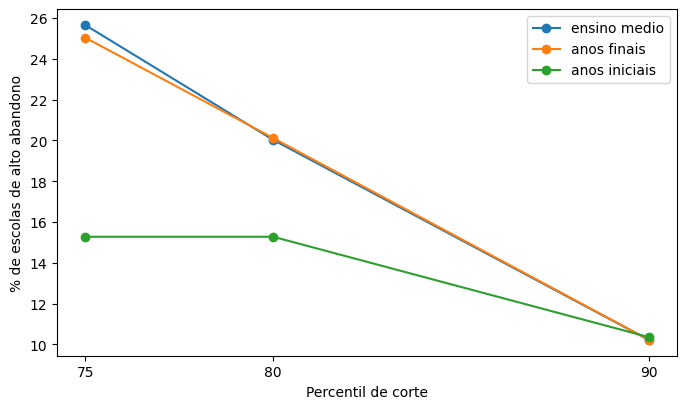

,etapa,percentil,limite,escolas_alto,pct_alto
0,ensino_medio,75,3.5,5447,25.66
1,ensino_medio,80,4.4,4252,20.03
2,ensino_medio,90,6.9,2170,10.22
3,anos_finais,75,1.3,11219,25.04
4,anos_finais,80,1.8,9014,20.12
5,anos_finais,90,3.6,4583,10.23
6,anos_iniciais,75,0.0,10801,15.28
7,anos_iniciais,80,0.0,10801,15.28
8,anos_iniciais,90,0.6,7324,10.36


In [8]:
linhas = []
for etapa in ETAPAS:
    taxa = df.loc[df["etapa"] == etapa, "taxa_abandono"]
    for p in [75, 80, 90]:
        alvo, limite = criar_alvo(taxa, p)
        linhas.append({"etapa": etapa, "percentil": p, "limite": limite,
                       "escolas_alto": int(alvo.sum()), "pct_alto": round(alvo.mean() * 100, 2)})
limiares = pd.DataFrame(linhas)
salvar(limiares, "10_limiares.csv", index=False)

fig, eixo = plt.subplots(figsize=(8, 4.5))
for etapa in ETAPAS:
    d = limiares[limiares["etapa"] == etapa]
    eixo.plot(d["percentil"], d["pct_alto"], marker="o", label=etapa.replace("_", " "))
eixo.set_xticks([75, 80, 90])
eixo.set_xlabel("Percentil de corte")
eixo.set_ylabel("% de escolas de alto abandono")
eixo.legend()
plt.savefig(os.path.join(SAIDA, "02_limiares.png"), dpi=300, bbox_inches="tight")
plt.show()
limiares

## Multicolinearidade, correlações, distribuições e ausência

In [9]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

m = df[NUMERICAS].fillna(df[NUMERICAS].median())
m = m.sample(20000, random_state=SEED)
m = (m - m.mean()) / m.std()
vif = pd.DataFrame({"variavel": NUMERICAS,
                    "VIF": [variance_inflation_factor(m.values, i) for i in range(m.shape[1])]})
vif = vif.sort_values("VIF", ascending=False).round(2)
salvar(vif, "11_vif.csv", index=False)
vif

,variavel,VIF
9,had_horas_aula,7.43
2,pct_integral,7.14
13,log_matriculas,2.72
0,indice_infra,2.31
4,afd_formacao_adequada,1.98
5,dsu_doc_superior,1.81
8,atu_alunos_turma,1.71
14,alunos_por_docente,1.58
11,inse_media,1.42
6,ied_esforco_alto,1.35


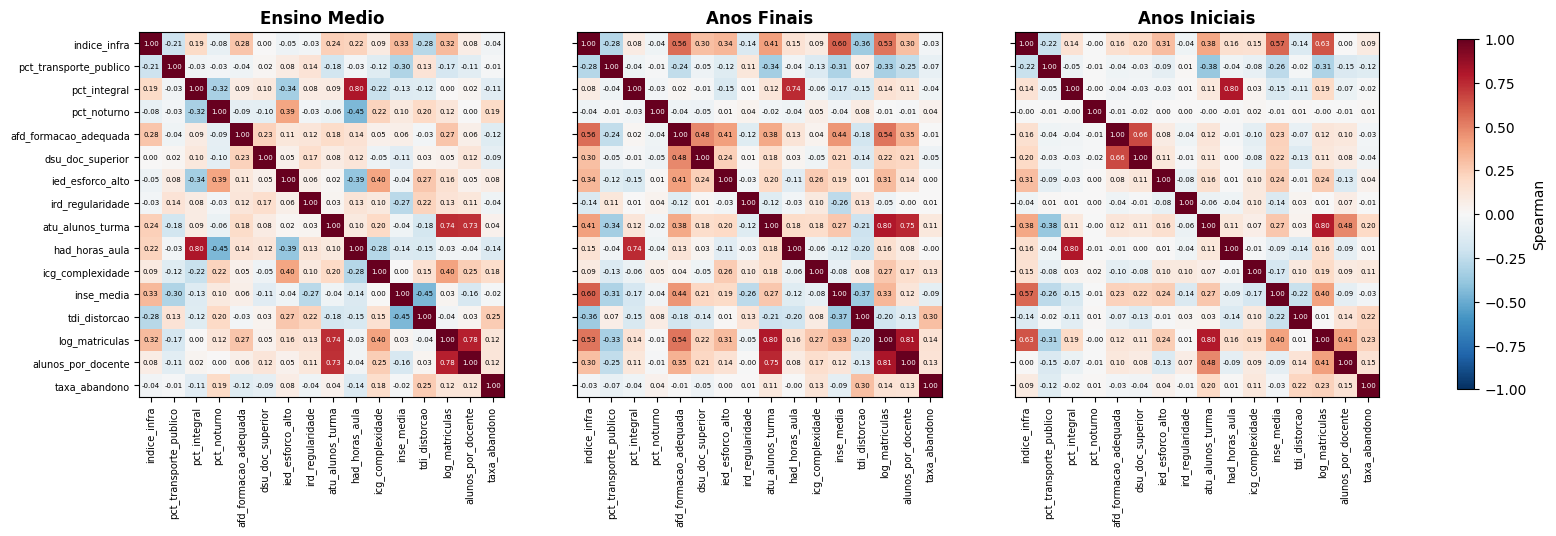

In [10]:
fig, eixos = plt.subplots(1, 3, figsize=(20, 6.5))
for i, etapa in enumerate(ETAPAS):
    corr = df.loc[df["etapa"] == etapa, NUMERICAS + ["taxa_abandono"]].corr(method="spearman")
    im = eixos[i].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    eixos[i].set_xticks(range(len(corr)))
    eixos[i].set_xticklabels(corr.columns, rotation=90, fontsize=7)
    eixos[i].set_yticks(range(len(corr)))
    eixos[i].set_yticklabels(corr.columns if i == 0 else [], fontsize=7)
    for a in range(len(corr)):
        for b in range(len(corr)):
            v = corr.iloc[a, b]
            eixos[i].text(b, a, f"{v:.2f}", ha="center", va="center", fontsize=5,
                          color="white" if abs(v) > 0.6 else "black")
    eixos[i].set_title(etapa.replace("_", " ").title(), fontweight="bold")
fig.colorbar(im, ax=eixos, shrink=0.7, label="Spearman")
plt.savefig(os.path.join(SAIDA, "03_matriz_correlacao.png"), dpi=300, bbox_inches="tight")
plt.show()

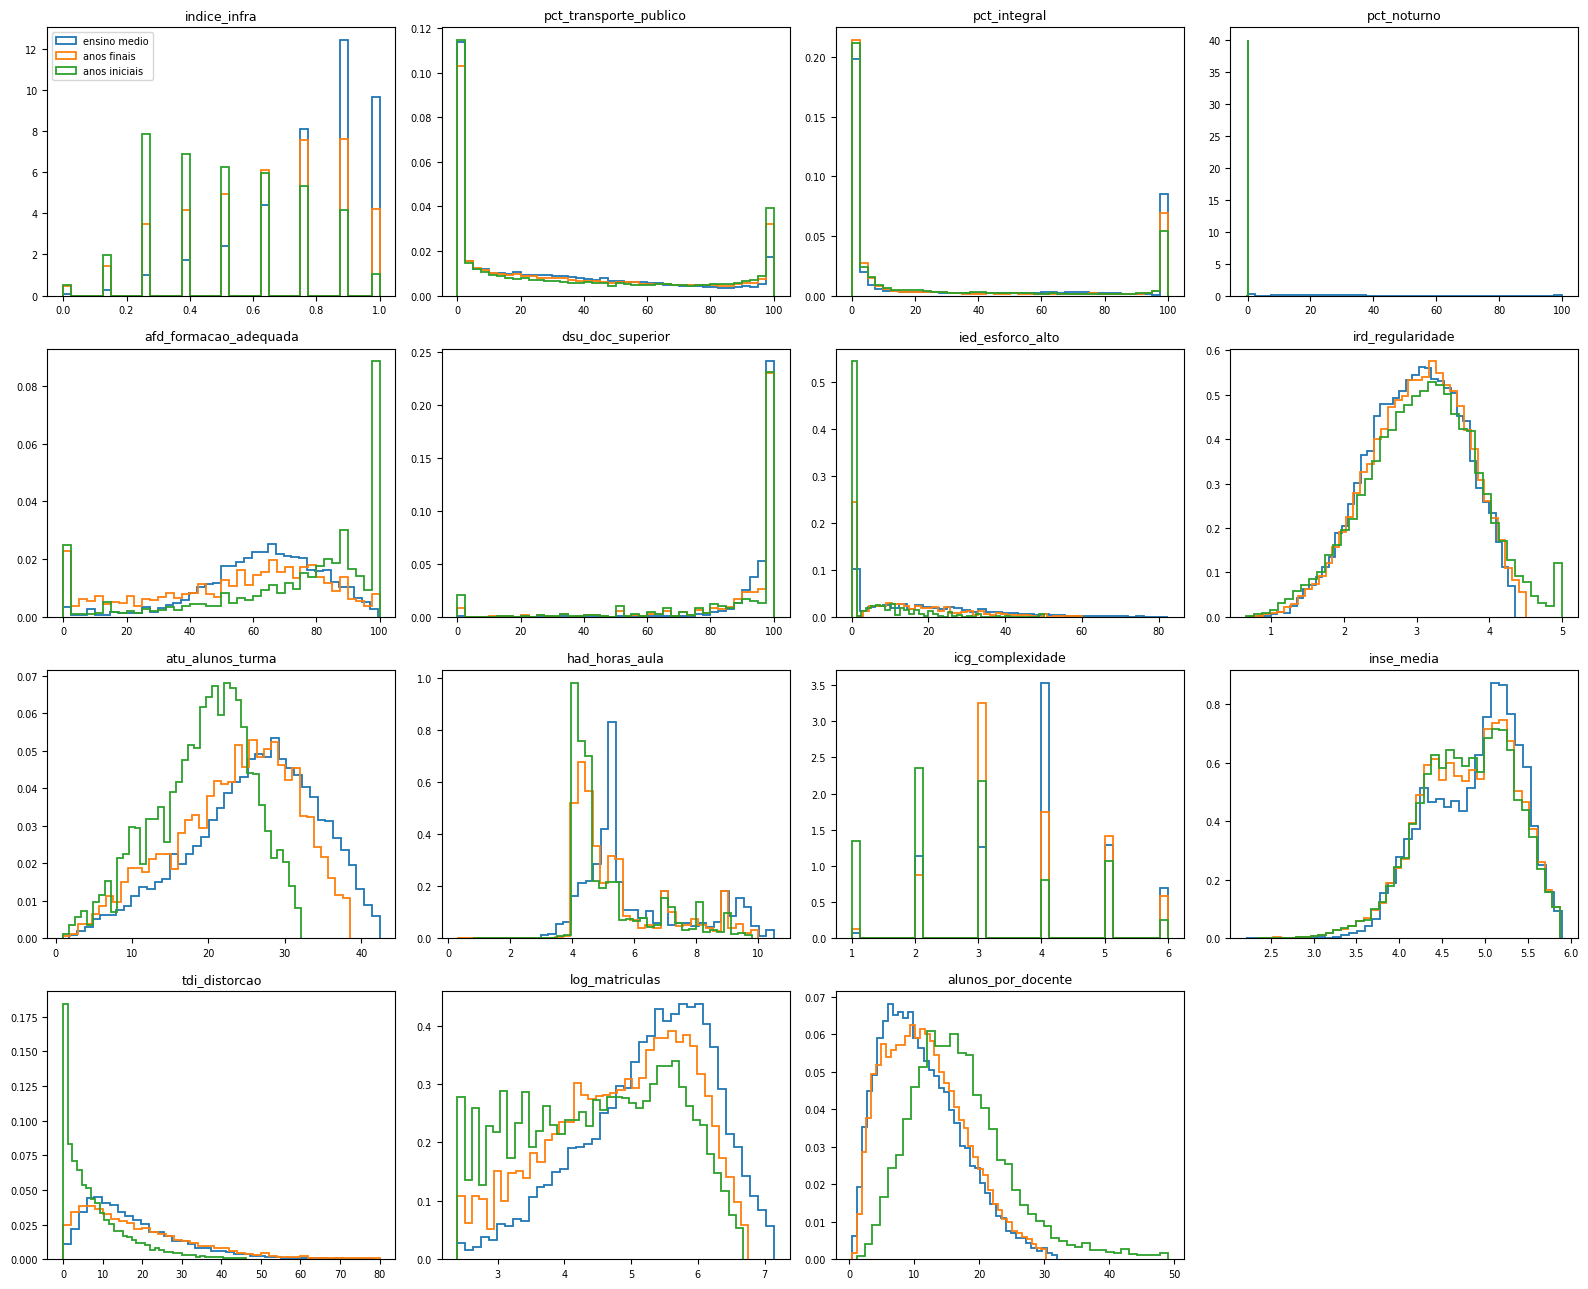

etapa,anos_finais,anos_iniciais,ensino_medio
indice_infra,0.0,0.0,0.0
pct_transporte_publico,0.0,0.0,0.0
pct_integral,0.0,0.0,0.0
pct_noturno,0.0,0.0,0.0
afd_formacao_adequada,0.1,14.8,0.0
dsu_doc_superior,0.1,14.8,0.0
ied_esforco_alto,0.1,14.8,0.0
ird_regularidade,1.6,2.5,3.2
atu_alunos_turma,9.1,22.6,0.0
had_horas_aula,0.0,0.0,0.0


In [11]:
fig, eixos = plt.subplots(4, 4, figsize=(16, 13))
eixos = eixos.ravel()
for i, var in enumerate(NUMERICAS):
    for etapa in ETAPAS:
        v = df.loc[df["etapa"] == etapa, var].dropna()
        eixos[i].hist(v[v <= v.quantile(0.99)], bins=40, histtype="step", density=True,
                      linewidth=1.3, label=etapa.replace("_", " "))
    eixos[i].set_title(var, fontsize=9)
    eixos[i].tick_params(labelsize=7)
for j in range(len(NUMERICAS), len(eixos)):
    eixos[j].axis("off")
eixos[0].legend(fontsize=7)
plt.tight_layout()
plt.savefig(os.path.join(SAIDA, "04_histogramas_preditoras.png"), dpi=300, bbox_inches="tight")
plt.show()

ausencia = df.groupby("etapa")[NUMERICAS].apply(lambda d: d.isna().mean().mul(100).round(1)).T
salvar(ausencia, "12_ausencia_por_etapa.csv")
ausencia

In [13]:
!zip -qr /content/02_eda.zip resultados/02_eda
from google.colab import files
files.download("/content/02_eda.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>